# 03: Preprocessing and baselines

This notebook turns `positions.parquet` into the modelling table, applies the evaluation design fixed
in `02_data_audit.ipynb`, and scores two baselines that use no learned weights. The learned models in
Milestone 3 are judged against these numbers.

The reusable pieces live in `src/chess_blunder/modelling.py`, so every later model sees the same
rows, features, folds and metrics.

In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(REPO_ROOT / 'src'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve

from chess_blunder import config, modelling

pd.set_option('display.width', 120)
FIG_DIR = config.REPORTS_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

positions = pd.read_parquet(config.PROCESSED_DIR / 'positions.parquet')

## 1. The modelling table

The target is **my** blunders, so the opponents' moves are dropped. The audit showed both sides
blunder at the same rate, so nothing about the base rate changes. `time_control` is split into base
seconds and increment so a model can use it as numbers.

In [2]:
table = modelling.modelling_table(positions)
print(f'all plies      : {len(positions):,}')
print(f'my moves       : {len(table):,} in {table.game_id.nunique():,} games')
print(f'blunder rate   : {table[modelling.TARGET].mean():.2%}')

all plies      : 260,030
my moves       : 130,048 in 4,008 games
blunder rate   : 9.18%


## 2. Features

Thirteen columns go in: eleven numeric, two categorical. Every one is known before the move is played.
The checks below make the leakage rule mechanical rather than a matter of care.

In [3]:
FEATURES = modelling.NUMERIC + modelling.CATEGORICAL

assert not set(FEATURES) & set(modelling.LEAKAGE), 'a leakage column is in the feature list'
assert modelling.TARGET not in FEATURES
assert set(FEATURES) <= set(table.columns), 'feature missing from the table'

print('numeric     :', ', '.join(modelling.NUMERIC))
print('categorical :', ', '.join(modelling.CATEGORICAL))
print('excluded    :', ', '.join(modelling.LEAKAGE + ['eco']))
table[FEATURES].isna().sum().loc[lambda s: s > 0].to_frame('missing rows')

numeric     : ply, pieces_white, pieces_black, material_diff, legal_moves, seconds_before, my_rating_pre, cp_before, win_before, tc_base, tc_increment
categorical : game_stage, mover
excluded    : seconds_spent, seconds_remaining, cp_after, cp_loss, win_after, win_loss, mate_sequence, mate_involved, eco


,missing rows
my_rating_pre,21


The only gap is `my_rating_pre` for the first game. It is median-imputed **inside each training fold**,
so the imputed value never draws on validation or test games.

`cp_before` and `win_before` carry the same information: one is a monotonic transform of the other, so both are kept for now. Trees are indifferent to that; a linear model in Milestone 3 should keep one.

## 3. Train/test split

The most recent 20% of games are the test set. They are set aside here and **not scored until
Milestone 3's final comparison**, so no choice made before then can be tuned to them.

In [4]:
is_test = modelling.time_split(table)
train, test = table[~is_test].reset_index(drop=True), table[is_test].reset_index(drop=True)

assert not set(train.game_id) & set(test.game_id), 'a game is on both sides of the split'
assert train.end_time.max() < test.end_time.min(), 'test games are not all later than training games'

pd.DataFrame({
    name: {'games': part.game_id.nunique(), 'moves': len(part), 'blunder rate': round(part[modelling.TARGET].mean(), 4),
           'first game': f'{part.end_time.min():%Y-%m-%d}', 'last game': f'{part.end_time.max():%Y-%m-%d}'}
    for name, part in [('train', train), ('test', test)]
}).T

,games,moves,blunder rate,first game,last game
train,3206,102880,0.0939,2022-10-11,2025-11-17
test,802,27168,0.0837,2025-11-17,2026-09-30


## 4. Cross-validation folds

All model comparison before Milestone 3's final test uses five folds over the training games,
grouped by `game_id`. The folds are built once and reused, so every model is scored on identical
validation sets.

In [5]:
folds = modelling.cv_folds(train)

for fit_idx, val_idx in folds:
    assert not set(train.game_id.iloc[fit_idx]) & set(train.game_id.iloc[val_idx]), 'game split across folds'

pd.DataFrame([
    {'fold': i, 'validation games': train.game_id.iloc[v].nunique(), 'validation moves': len(v),
     'blunder rate': round(train[modelling.TARGET].iloc[v].mean(), 4)}
    for i, (_, v) in enumerate(folds)
]).set_index('fold')

,validation games,validation moves,blunder rate
fold,,,
0,642,20911,0.0942
1,641,20200,0.0972
2,641,20471,0.0943
3,641,20652,0.0931
4,641,20646,0.0908


## 5. The preprocessor

Learned models in Milestone 3 will sit behind this transformer: median imputation and standard
scaling for numeric columns, one-hot encoding for the categorical ones. Fitting it on one training
fold shows the matrix a model will receive.

In [6]:
fit_idx, _ = folds[0]
pre = modelling.make_preprocessor().fit(train.iloc[fit_idx])
X = pre.transform(train.iloc[fit_idx])

print(f'matrix: {X.shape[0]:,} rows x {X.shape[1]} columns, {np.isnan(X).sum()} missing')
print(list(pre.get_feature_names_out()))

matrix: 81,969 rows x 16 columns, 0 missing
['numeric__ply', 'numeric__pieces_white', 'numeric__pieces_black', 'numeric__material_diff', 'numeric__legal_moves', 'numeric__seconds_before', 'numeric__my_rating_pre', 'numeric__cp_before', 'numeric__win_before', 'numeric__tc_base', 'numeric__tc_increment', 'categorical__game_stage_endgame', 'categorical__game_stage_middlegame', 'categorical__game_stage_opening', 'categorical__mover_black', 'categorical__mover_white']


## 6. Baselines

Two reference points, neither with learned weights:

- **Base rate**: every move gets the training blunder rate. It cannot rank moves, so its ROC-AUC is
  0.5 and its PR-AUC is the base rate: the no-skill floor.
- **Stage × complexity**: the training blunder rate in each cell of game stage × legal-moves bucket
  (18 cells). The audit showed both features matter, so this measures how much risk can be read off
  position complexity with a lookup table and nothing else.

In [7]:
baselines = {
    'base rate': modelling.BaseRate(),
    'stage x complexity': modelling.StageComplexityRate(),
}
cv = {name: modelling.cross_validate(model, train, folds) for name, model in baselines.items()}

summary = pd.concat(
    {name: scores.agg(['mean', 'std']).T for name, scores in cv.items()}, names=['baseline', 'metric']
).unstack('metric')
summary.columns = [f'{stat} {metric}' for stat, metric in summary.columns]
summary = summary[[f'{s} {m}' for m in ('pr_auc', 'roc_auc', 'brier') for s in ('mean', 'std')]].round(4)
summary.to_csv(config.REPORTS_DIR / 'baselines_cv.csv')
summary

,mean pr_auc,std pr_auc,mean roc_auc,std roc_auc,mean brier,std brier
baseline,,,,,,
base rate,0.0939,0.0023,0.5000,0.0000,0.0851,0.0019
stage x complexity,0.1320,0.0034,0.6383,0.0044,0.0833,0.0018


In [8]:
rule = modelling.StageComplexityRate().fit(train, train[modelling.TARGET])
pd.DataFrame({
    'blunder rate': rule.table_.round(3),
    'training moves': rule._cells(train).value_counts(),
})

,blunder rate,training moves
"endgame | (0.0, 10.0]",0.032,4597
"endgame | (10.0, 20.0]",0.059,4376
"endgame | (20.0, 30.0]",0.054,2327
"endgame | (30.0, 40.0]",0.015,546
"endgame | (40.0, 50.0]",0.013,157
"endgame | (50.0, inf]",0.000,22
"middlegame | (0.0, 10.0]",0.052,7840
"middlegame | (10.0, 20.0]",0.043,3690
"middlegame | (20.0, 30.0]",0.094,15815
"middlegame | (30.0, 40.0]",0.138,22278


The table repeats the audit's pattern: risk rises with the number of legal moves in the opening and
middlegame. Some cells are thin: an endgame with more than 50 legal moves is rare, and a rate from a
handful of moves is noisy. That is one of the limits a learned model should improve on.

### Precision and recall of the rule baseline

PR-AUC compresses a curve into one number. The curve itself, from out-of-fold predictions, shows what
the rule baseline offers at each operating point, against the base-rate line it has to clear.

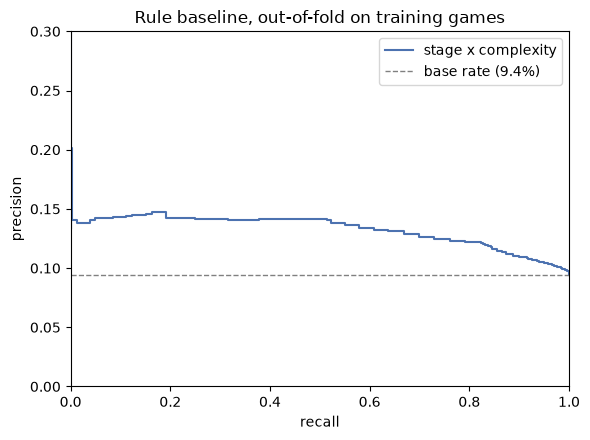

In [9]:
oof = np.zeros(len(train))
for fit_idx, val_idx in folds:
    model = modelling.StageComplexityRate().fit(train.iloc[fit_idx], train[modelling.TARGET].iloc[fit_idx])
    oof[val_idx] = model.predict_proba(train.iloc[val_idx])[:, 1]

precision, recall, _ = precision_recall_curve(train[modelling.TARGET], oof)
base = train[modelling.TARGET].mean()

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.step(recall, precision, where='post', color='#4c72b0', label='stage x complexity')
ax.axhline(base, ls='--', c='grey', lw=1, label=f'base rate ({base:.1%})')
ax.set(xlabel='recall', ylabel='precision', xlim=(0, 1), ylim=(0, 0.3),
       title='Rule baseline, out-of-fold on training games')
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / '03_baseline_pr_curve.png', dpi=150)

## What this establishes

- The modelling table is my 130,048 moves, with thirteen features that are all known before the move.
  The leakage exclusions are enforced by assertions, not by care.
- The test set is the most recent 20% of games and is untouched until Milestone 3.
- Five grouped folds over the training games are fixed, so every model is compared on the same
  validation sets.
- The preprocessor imputes and scales inside each fold, so nothing about validation or test games
  leaks into training.
- The baselines set the bar (cross-validated, mean ± std over five folds, in
  `reports/baselines_cv.csv`):

  | baseline           | PR-AUC          | ROC-AUC         | Brier           |
  | ------------------ | --------------- | --------------- | --------------- |
  | base rate          | 0.094 ± 0.002   | 0.500           | 0.085 ± 0.002   |
  | stage × complexity | 0.132 ± 0.003   | 0.638 ± 0.004   | 0.083 ± 0.002   |

  Position complexity alone lifts PR-AUC by about 40% over no skill. A learned model has to beat the
  stage × complexity table to show it has found anything beyond "complicated positions are risky".

**Next (Milestone 3):** at least two learned models, a logistic regression and a tree ensemble, behind `make_preprocessor`, compared on these folds, then scored once on the test set, followed by
error analysis.